In [76]:
import torch
from torch import nn, optim
import matplotlib.pyplot as plt

In [77]:
def my_muon(W, lr):
    lr_scale = max(1, W.shape[0] / W.shape[1]) ** 0.5
    return optim.Muon(
        [W], lr=lr / lr_scale,
        momentum=0.0, nesterov=False, weight_decay=0.0,
        ns_coefficients=(1.5, -0.5, 0.0), ns_steps=10,
        adjust_lr_fn="original",
    )

In [78]:
torch.manual_seed(123)
N = 100
input = torch.randn(N, 5)
mystery = torch.randn(3, 5)
output = input @ mystery.T + torch.randn(N, 3) * 0.1

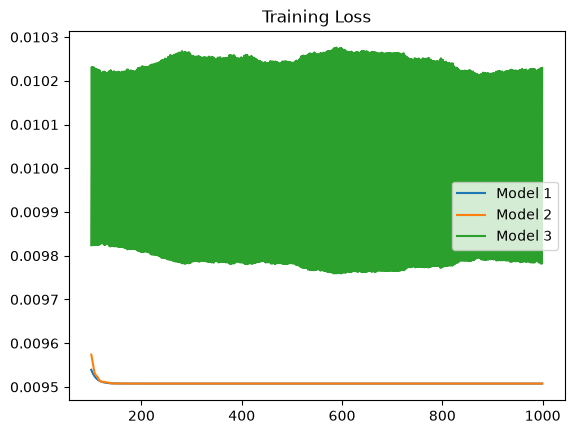

In [79]:
models = [nn.Linear(5, 3, bias=False) for _ in range(3)]
criterion = nn.MSELoss()
optimizers  = [
    optim.SGD(models[0].parameters(), lr=0.1),
    optim.Adam(models[1].parameters(), lr=0.1),
    my_muon(models[2].weight, lr=0.04)
]

losses = [[] for _ in range(3)]
epochs = 1000
for epoch in range(epochs):
    for model, optimizer, loss_table in zip(models, optimizers, losses):
        optimizer.zero_grad()
        predictions = model(input)
        loss = criterion(predictions, output)
        loss_table.append(loss.item())
        loss.backward()
        optimizer.step()

for i, loss_table in enumerate(losses):
    plt.plot(range(100, epochs), loss_table[100:], label=f'Model {i+1}')
plt.legend()
plt.title('Training Loss')
plt.show()